# mpNRG validation: multipoint NRG in Julia

`MultipointNRG` is a full-density-matrix NRG for quantum impurity models with a finite local Fock space,
computing thermodynamics, thermal averages and local **2p, 3p and 4p partial spectral functions** (PSFs), following

> S.-S. B. Lee, F. B. Kugler and J. von Delft, *Computing local multipoint correlators using the numerical
> renormalization group*, [Phys. Rev. X **11**, 041007 (2021)](https://doi.org/10.1103/PhysRevX.11.041007) ("Lee"),

with the PSF convention of Kugler, Lee & von Delft, PRX **11**, 041006 (2021), Eq. (28) ("Kugler"), shared with the
repository's `HubbardAtom` package. This notebook runs the validation ladder of the task sheet (`mpNRG/docs/TASK.md`,
Sec. 6), one section per item, and prints the achieved accuracies recorded in `mpNRG/STATUS.md`. The unit tests
(`julia --project=mpNRG/test mpNRG/test/runtests.jl`) assert the same checks.

**Provenance.** Every equation used was read from the arXiv LaTeX source of the papers (never from a PDF text layer).
Lee's PSF of operators **in permuted order** $(\mathcal O^1,\dots,\mathcal O^\ell)$:

$$
S[\mathcal O^1,\dots,\mathcal O^\ell](\varepsilon_1,\dots,\varepsilon_{\ell-1})
=\sum_{\underline 1\cdots\underline\ell}\rho_{\underline 1}\prod_{i=1}^{\ell-1}
\Bigl[O^i_{\underline i\,\underline{i+1}}\,\delta\bigl(\varepsilon_i-E_{\underline{i+1}}+E_{\underline 1}\bigr)\Bigr]
O^\ell_{\underline\ell\,\underline 1}\qquad\text{(Lee Eq. (5))}.
$$

**Exactness tests V1–V4** must hold to rounding; V5–V8 compare with physics and external data.

In [1]:
using MultipointNRG, LinearAlgebra, Printf, Random, JLD2
import HubbardAtom as HA
using CairoMakie
CairoMakie.activate!(type = "png")
include(joinpath(@__DIR__, "..", "test", "helpers.jl"))      # independent JW construction, ED helpers
include(joinpath(@__DIR__, "..", "test", "as_helpers.jl"))   # explicit Anders-Schiller basis
FIG = joinpath(@__DIR__, "figures", "mpnrg"); mkpath(FIG)
savefig(name, fig) = (save(joinpath(FIG, name * ".png"), fig; px_per_unit = 2); save(joinpath(FIG, name * ".pdf"), fig); fig)
println("Julia ", VERSION, ", threads ", Threads.nthreads(), ", MultipointNRG ", pkgversion(MultipointNRG))
RESULTS = Dict{String,Any}()   # the numbers recorded in STATUS.md

Julia 1.13.0, threads 4, MultipointNRG 0.1.0


Dict{String, Any}()

## V1. Algebra: symmetry layer, fusion and fermionic signs (P1, P3)

Abelian labels (U1, Z_n, always with the fermion parity), block-sparse operators, the fusion map and the two
representation rules of the fermionic order $c^\dagger_N\cdots c^\dagger_{-1}|0\rangle$ (derived in STATUS.md):
(R1) an operator of parity $p$ on earlier sites acts as $Z_n^p\otimes O$; (R2) an operator on site $n$ acts as
$O_n\otimes 1$. Checked against an **independent** Kronecker-product Jordan–Wigner construction (`test/helpers.jl`).

In [2]:
# block algebra against dense matrices, random operators with random shifts
rng = MersenneTwister(7)
G = SymmetryGroup(U1(:N), U1(:twoSz))
V = SectorSpace(Dict(sector(G, [n, s, mod(n, 2)]) => rand(rng, 1:4) for n in -1:3 for s in -3:3))
function randop(Δ)
    A = BlockOp{Float64}(V, V, Δ)
    for q in sectors(V)
        haskey(V, fuse(q, Δ)) && setblock!(A, q, randn(rng, dim(V, fuse(q, Δ)), dim(V, q)))
    end
    A
end
shifts = [sector(G; N = 1, twoSz = 1), sector(G; N = -1, twoSz = 1), neutral(G), sector(G; N = 0, twoSz = 2, Pf = 0)]
err_alg = 0.0; err_tr = 0.0
for Δa in shifts, Δb in shifts
    A = randop(Δa); B = randop(Δb)
    global err_alg = max(err_alg, norm(todense(A * B) - todense(A) * todense(B)) / (norm(todense(A)) * norm(todense(B))))
    C = A * B
    global err_tr = max(err_tr, isneutral(C.shift) ? abs(tr(C) - tr(todense(C))) / (1 + abs(tr(todense(C)))) : abs(tr(C)))
end
@printf("block products vs dense: %.1e (relative); traces: %.1e (non-neutral products give exactly 0)\n", err_alg, err_tr)
RESULTS["V1_block"] = max(err_alg, err_tr)

# the first three Wilson sites: shell construction vs independent Jordan-Wigner
m = siam(U = 0.6, εd = -0.25, Δ = 0.1); N = 2
run = run_nrg(m, NRGParams(N = N, Nkeep = typemax(Int)))
ms = chain_modes(n -> site_modes(m, n), N); c = jw_annihilators(length(ms)); idx(md) = findfirst(==(md), ms)
emb = dense_embedding(run, N); sh = shell(run, N)
err_ops = 0.0; err_ac = 0.0
ops = Dict(md => project(run, cop(md), N) for md in ms)
for md in ms, (q, M) in ops[md].blocks
    global err_ops = max(err_ops, norm(emb.cols[target(ops[md], q)]' * c[idx(md)] * emb.cols[q] - M))
end
Id = todense(identity_op(sh.space))
for a in ms, b in ms
    X = todense(ops[a] * ops[b]' + ops[b]' * ops[a]); Y = todense(ops[a] * ops[b] + ops[b] * ops[a])
    global err_ac = max(err_ac, norm(X - (a == b ? Id : 0Id)), norm(Y))
end
Hd = densematrix(hamiltonian_expr(m, run.chains, N), FockBasis(ms))
err_H = maximum(norm(emb.cols[q]' * Hd * emb.cols[q] - Diagonal(sh.E[q] .+ sh.shift)) for q in sectors(sh.space))
@printf("%d mode operators through the shell construction vs dense JW: %.1e\n", length(ms), err_ops)
@printf("canonical anticommutators {c_i, c_j†} = δ_ij, {c_i, c_j} = 0 in the shell basis: %.1e\n", err_ac)
@printf("H_N from blocks vs dense H_N: %.1e\n", err_H)
RESULTS["V1_signs"] = max(err_ops, err_ac, err_H)

# symmetry violation is detected and named
Gs, Q = spin_symmetry(:charge_spin); S = labeltype(Gs)
imp = LocalSpace(-1, [:up, :dn], Dict{Mode,S}(Mode(-1, :up) => Q(:up), Mode(-1, :dn) => Q(:dn)))
chans = [BathChannel(σ, Q(σ), BoxHybridization(0.1); coupling = cop(Mode(-1, σ))) for σ in (:up, :dn)]
try
    ImpurityModel(Gs, imp, 0.1 * (cdag(Mode(-1, :up)) * cop(Mode(-1, :dn)) + cdag(Mode(-1, :dn)) * cop(Mode(-1, :up))), chans)
catch e
    println("transverse field with U1(:twoSz): ", e.msg[1:min(end, 140)], " …")
end

block products vs dense: 7.9e-18 (relative); traces: 9.7e-16 (non-neutral products give exactly 0)
8 mode operators through the shell construction vs dense JW: 1.4e-15
canonical anticommutators {c_i, c_j†} = δ_ij, {c_i, c_j} = 0 in the shell basis: 6.7e-14
H_N from blocks vs dense H_N: 1.9e-14
transverse field with U1(:twoSz): the local Hamiltonian breaks the declared symmetry factor(s) [:twoSz] of U1(:N) × U1(:twoSz) × Z2(:Pf); drop twoSz from the symmetry group …


## V2. Bath discretization and Wilson chain (P2)

Logarithmic intervals bounded by $\pm D\Lambda^{-k-z}$ (Lee p. 23), Žitko–Pruschke representative energies (Lee's
Ref. [23]; closed form for the box, App. B ODE otherwise), tridiagonalization in `BigFloat` with a two-precision
self-check.

sum rule Σ|V_k|² = 2DΔ/π, all z and schemes: 0.0e+00
chain moments vs star moments up to order 2N+1 (BigFloat): 1.5e-154
Žitko-Pruschke ODE (App. B, backward RK4) vs closed form: 1.3e-13
two-precision check (256 vs 512 bits): max relative deviation 7.1e-77


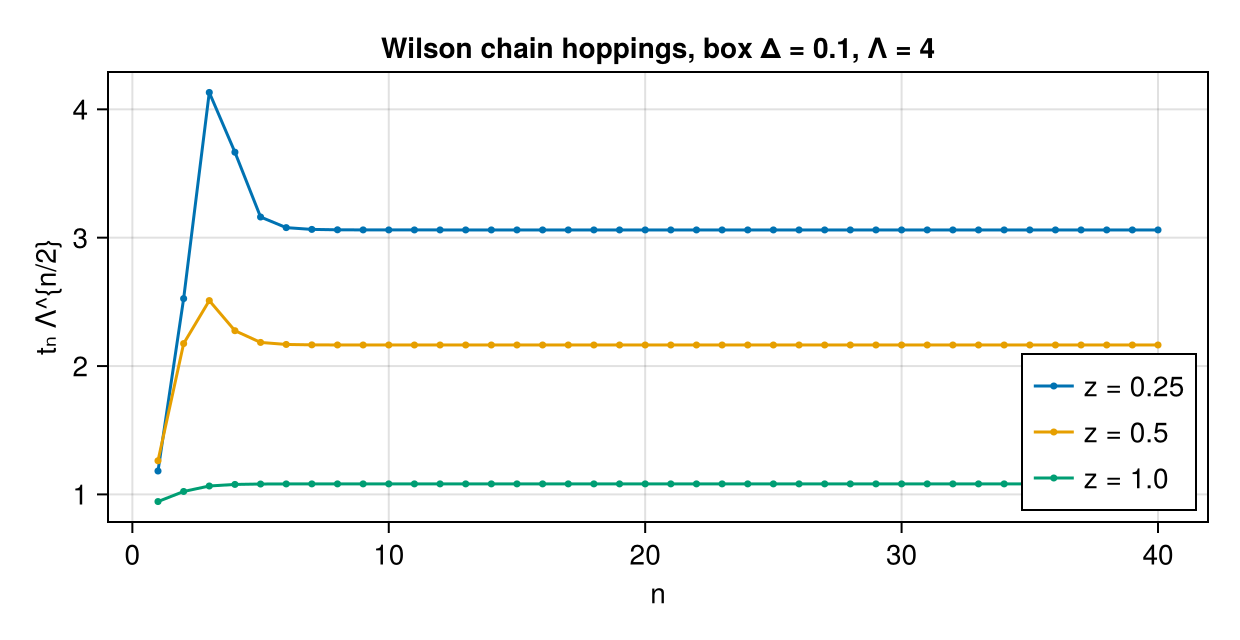

In [3]:
h = BoxHybridization(0.1)
sr = maximum(abs(Float64(sum(discretize(h, Discretization(Λ = 4.0, z = z, scheme = sc), 30).V .^ 2)) - 2 * 0.1 / π)
             for z in (0.25, 0.5, 0.75, 1.0), sc in (:zitko, :wilson, :campo))
@printf("sum rule Σ|V_k|² = 2DΔ/π, all z and schemes: %.1e\n", sr)
star = setprecision(() -> discretize(h, Discretization(Λ = 4.0, z = 0.5), 24), BigFloat, 512)
ε, t = lanczos_chain(star, 13; prec = 512)
mom = setprecision(BigFloat, 512) do
    maximum(Float64(abs(star_moments(star, k) - chain_moments(ε, t, k)) / star_moments(star, 0)) for k in 0:25)
end
@printf("chain moments vs star moments up to order 2N+1 (BigFloat): %.1e\n", mom)
d = Discretization(Λ = 4.0, z = 0.3)
ode = maximum(abs.(Float64.(MultipointNRG._zitko_box(d, 1.0, 20, BigFloat)) .- zitko_energies(MultipointNRG._OneSide{typeof(h),Float64}(h, 1), d, 1.0, 20)) ./
              Float64.(MultipointNRG._zitko_box(d, 1.0, 20, BigFloat)))
@printf("Žitko-Pruschke ODE (App. B, backward RK4) vs closed form: %.1e\n", ode)
chains = Dict(z => wilson_chain(h, 40; z = z) for z in (0.25, 0.5, 1.0))
@printf("two-precision check (256 vs 512 bits): max relative deviation %.1e\n", maximum(c.precision_check.max_relative_deviation for c in values(chains)))
RESULTS["V2"] = (sumrule = sr, moments = mom, ode = ode)
fig = Figure(size = (620, 320))
ax = Axis(fig[1, 1], xlabel = "n", ylabel = "tₙ Λ^{n/2}", title = "Wilson chain hoppings, box Δ = 0.1, Λ = 4")
for (z, c) in sort(collect(chains); by = first)
    scatterlines!(ax, 1:40, [c.t[n + 1] * 4.0^(n / 2) for n in 1:40]; label = "z = $z", markersize = 5)
end
axislegend(ax; position = :rb)
savefig("v2_chain", fig)

## V3. No-truncation exactness against ED (P3, P5, P6–P8)

With $N_{\rm keep}$ larger than every shell, all states are discarded only at $n=N$ and the Anders–Schiller basis is
the exact eigenbasis. Energies, $Z$, thermal averages and **all permutations** of 2p, 3p and 4p PSFs must equal the
reference ED of the same finite chain (`reference/`, independent of `nrg/`), unbinned (`exact = true`) and binned
against identically binned ED data. Operators include $d_\sigma, d^\dagger_\sigma, n_{d\sigma}$, the composite
$q_\uparrow=[d_\uparrow,H_{\rm int}]$, the bosonic $\{q_\uparrow,d^\dagger_\downarrow\}$, and the impurity–site-0
operator $d^\dagger_\downarrow f_{0\downarrow}$. Positions and weights are compared through the Fourier test functions
$\sum_j w_j e^{i k\cdot\varepsilon_j}$ on a grid of $k$.

In [4]:
m = siam(U = 0.5, εd = -0.1, Δ = 0.1); T = 0.05
g = LogGrid(emin = 1e-5, emax = 10.0, ndec = 16)
Hint = 0.5 * n_(:up) * n_(:dn); q(σ) = comm(d_(σ), Hint)
bos = acomm(q(:up), dd_(:dn)); x = dd_(:dn) * f0_(:dn)
v3 = Dict{String,Float64}()
for (N, families) in ((1, [(d_(:up), dd_(:up)), (q(:up), dd_(:up)), (x, x'), (bos, bos'),
                           (d_(:up), dd_(:up), n_(:dn)), (q(:up), dd_(:dn), bos'),
                           (d_(:up), dd_(:up), d_(:dn), dd_(:dn)), (q(:up), dd_(:up), d_(:dn), dd_(:dn))]),
                      (2, [(d_(:up), dd_(:up)), (d_(:up), dd_(:up), n_(:dn)), (d_(:up), dd_(:dn), d_(:dn), dd_(:up))]))
    run = run_nrg(m, NRGParams(N = N, Nkeep = typemax(Int))); f = fdm(run; T = T)
    ed = model_ed(m, run.chains, N, T)
    shN = shell(run, N)
    v3["energies"] = max(get(v3, "energies", 0.0), maximum(abs.(sort(vcat([shN.E[q] .+ shN.shift for q in sectors(shN.space)]...)) .- sort(vcat(values(ed.E)...)))))
    v3["logZ"] = max(get(v3, "logZ", 0.0), abs(f.logZ - log(ed.Z)))
    for o in (n_(:up), n_(:up) * n_(:dn), x + x', q(:up) * q(:up)')
        v3["thermal"] = max(get(v3, "thermal", 0.0), abs(thermal_average(run, f, o) - ed_thermal_average(ed, o)))
    end
    for ops in families
        ℓ = length(ops)
        perms = N == 1 ? all_perms(ℓ) : [collect(1:ℓ)]
        for p in perms
            o = Tuple(ops[i] for i in p)
            r = psf(run, f, o; exact = true, max_terms = 20_000_000); P, w = ed_psf(ed, o)
            r.meta[:pruned] && continue
            e = test_functions_error(r.positions, r.weights, P, w)
            rb = psf(run, f, o; grid = g)
            eb = dict_maxdiff(hist_dict(rb), bin_terms(P, w, g))
            v3["$(ℓ)p exact"] = max(get(v3, "$(ℓ)p exact", 0.0), e)
            v3["$(ℓ)p binned"] = max(get(v3, "$(ℓ)p binned", 0.0), eb)
        end
    end
end
for k in sort(collect(keys(v3))); @printf("%-12s %.1e\n", k, v3[k]); end
RESULTS["V3"] = v3

2p binned    3.4e-15
2p exact     1.1e-14
3p binned    2.3e-15
3p exact     8.5e-15
4p binned    3.1e-15
4p exact     1.4e-14
energies     5.3e-15
logZ         1.2e-14
thermal      4.3e-15


Dict{String, Float64} with 9 entries:
  "4p binned" => 3.10862e-15
  "logZ"      => 1.15463e-14
  "energies"  => 5.32907e-15
  "3p exact"  => 8.53723e-15
  "thermal"   => 4.27436e-15
  "3p binned" => 2.33147e-15
  "4p exact"  => 1.44048e-14
  "2p binned" => 3.35842e-15
  "2p exact"  => 1.06776e-14

**V3(b, c) — `HubbardAtom` references.** (b) The repository's `HubbardAtom.AIMModel(U, β, ε, V)` on the star
$(E_k,V_k)$ of the finite chain (unitarily equivalent, so impurity PSFs are identical). (c) The Hubbard-atom limit
$t_0=0$ against `HubbardAtom`'s exact atom PSFs.

In [5]:
U = 0.4; T = 0.05; N = 2
m = siam(U = U, Δ = 0.1)
run = run_nrg(m, NRGParams(N = N, Nkeep = typemax(Int))); f = fdm(run; T = T)
E, Vk = chain_star(run.chains[1], N)
ha = HA.AIMModel(U, 1 / T, E, Vk); sp = HA.spectrum(ha); c = HA.operators(ha).c
ha_mat(ts) = (reduce(hcat, [t.position for t in ts]), [t.weight for t in ts])
e3b = maximum(begin
    r = psf(run, f, mine; exact = true, max_terms = 20_000_000)
    P, w = ha_mat(HA.psf_chain(sp, theirs; otol = 1e-13))
    test_functions_error(r.positions, r.weights, P, w)
end for (mine, theirs) in [((d_(:up), dd_(:up)), (c[1], c[1]')), ((d_(:up), dd_(:up), n_(:dn)), (c[1], c[1]', c[2]' * c[2])),
                           ((d_(:up), dd_(:dn), d_(:dn), dd_(:up)), (c[1], c[2]', c[2], c[1]'))])
@printf("V3(b) vs HubbardAtom.AIMModel on the star of the finite chain (2p, 3p, 4p): %.1e\n", e3b)
U = 0.6; T = 0.1
m = siam(U = U, Δ = 0.1)
chs = [MultipointNRG.WilsonChain(c.eps, vcat(0.0, c.t[2:end]), c.hyb, c.disc, c.nint, c.precision_check) for c in wilson_chains(m, 2)]
run = run_nrg(m, NRGParams(N = 2, Nkeep = typemax(Int)); chains = chs); f = fdm(run; T = T)
atom = HA.HubbardAtomModel(U, 1 / T); sp = HA.spectrum(atom); o = HA.operators(atom)
e3c = maximum(begin
    r = psf(run, f, mine; exact = true, max_terms = 20_000_000)
    P, w = ha_mat(HA.psf(sp, theirs))
    test_functions_error(r.positions, r.weights, P, w)
end for (mine, theirs) in [((d_(:up), dd_(:up)), (o.d_up, o.dag_up)), ((d_(:up), dd_(:up), n_(:dn)), (o.d_up, o.dag_up, o.n_dn)),
                           ((d_(:up), dd_(:dn), d_(:dn), dd_(:up)), (o.d_up, o.dag_dn, o.d_dn, o.dag_up))])
@printf("V3(c) atom limit vs HubbardAtom exact atom PSFs (2p, 3p, 4p): %.1e\n", e3c)
RESULTS["V3bc"] = (b = e3b, c = e3c)

V3(b) vs HubbardAtom.AIMModel on the star of the finite chain (2p, 3p, 4p): 4.7e-14
V3(c) atom limit vs HubbardAtom exact atom PSFs (2p, 3p, 4p): 2.5e-14


(b = 4.747979617071236e-14, c = 2.5107982731322426e-14)

## V4. Exactness with truncation (P4, P5, P6–P8)

A tiny chain ($N=3$, full dimension 1024) with $N_{\rm keep}=20$, so that KK, KD, DK and DD sectors and all
refinement terms occur. The Anders–Schiller basis is built **explicitly** as dense vectors on the full chain.

* (b) The shell-diagonal expansion $\sum_n\sum_{X\bar X\neq KK}\mathcal O^n_{X\bar X}$ reassembles every local
  operator exactly (Lee p. 9). Odd operators carry the environment parity $(-1)^{N_e}$ in their AS matrix elements
  (STATUS.md), which cancels in every trace.
* (c) ${\rm Tr}\,\varrho=1$, $\bar\rho^n\ge0$, and $\bar\rho^n$ equals the partial trace of the dense $\varrho$.
* (a) Every PSF's total weight equals ${\rm Tr}[\varrho\,\mathcal O^1\cdots\mathcal O^\ell]$, computed by `fdm/` and by
  brute force with the dense $\varrho$.
* (d) A chain with $t_n=\epsilon_n=0$ beyond $n_c$: the AS states are exact eigenstates and the K sectors refine
  into exactly degenerate states, so Lee's formulas are exact **with truncation** — positions included.
* (e) An independent dense brute-force implementation of the recursion (`test/test_v4e_dense.jl`) on a spinless
  chain: bin-by-bin agreement of 2p/3p/4p histograms (a deliberate engine bug is detected by it).

In [6]:
m = siam(U = 0.5, εd = -0.1, Δ = 0.1); N = 3; T = 0.03
run = run_nrg(m, NRGParams(N = N, Nkeep = 20)); f = fdm(run; T = T)
println("n₀ = ", run.n0, ", kept per shell ", [totalkept(sh) for sh in run.shells], ", discarded ", [totaldisc(sh) for sh in run.shells])
U4 = as_basis(run); ms = chain_modes(n -> site_modes(m, n), N); B = FockBasis(ms); dense(o) = densematrix(o, B)
ops = Dict("d↑" => d_(:up), "d†↑" => dd_(:up), "n↓" => n_(:dn), "d↓" => d_(:dn), "d†↓" => dd_(:dn),
           "q↑" => comm(d_(:up), 0.5 * n_(:up) * n_(:dn)), "x" => dd_(:dn) * f0_(:dn))
e4b = 0.0
for (name, o) in ops
    S = zeros(4^(N + 2), 4^(N + 2))
    for n in max(run.n0, maxsite(o)):N, X in (:K, :D), Xb in (:K, :D)
        (X === :K && Xb === :K) && continue
        S .+= as_embed(run, U4, project(run, o, n), n, X, Xb)
    end
    global e4b = max(e4b, norm(S - dense(o)) / max(1, norm(dense(o))))
end
ρ = as_rho(run, U4, f)
e4c = abs(tr(ρ) - 1)
for n in run.n0:N
    sh = shell(run, n); dn = size(U4[n].cols[first(sectors(sh.space))], 1); de = 4^(N - n)
    R = reshape(ρ, dn, de, dn, de); red = sum(R[:, e, :, e] for e in 1:de)
    for q in sectors(sh.space)
        global e4c = max(e4c, norm(U4[n].cols[q]' * red * U4[n].cols[q] - MultipointNRG.rho_full(f, run, n, q)))
    end
end
g = LogGrid(emin = 1e-6, emax = 10.0, ndec = 16)
e4a = 0.0
for tup in [("d↑", "d†↑"), ("q↑", "d†↑"), ("d↑", "d†↑", "n↓"), ("x", "d↑", "d†↑"), ("d↑", "d†↑", "d↓", "d†↓"),
            ("d↑", "d†↓", "d↓", "d†↑"), ("q↑", "d†↓", "d↓", "d†↑")]
    os = Tuple(ops[nm] for nm in tup)
    r = psf(run, f, os; grid = g)
    global e4a = max(e4a, abs(r.total - tr(ρ * dense(reduce(*, os)))), abs(r.total - r.meta[:sum_rule]))
end
@printf("V4b shell-diagonal expansion reassembles local operators: %.1e\n", e4b)
@printf("V4c Tr ϱ = 1, ρ̄ⁿ = partial trace of ϱ: %.1e;  min eigenvalue of ρ̄: %.1e\n", e4c, f.info[:checks].min_eigenvalue)
@printf("V4a total weights vs Tr[ϱ O¹⋯Oˡ] (FDM and dense brute force), ℓ = 2, 3, 4: %.1e\n", e4a)
# V4d
chs = decoupled_tail(wilson_chains(m, N), 1)
rund = run_nrg(m, NRGParams(N = N, Nkeep = 40); chains = chs); fd = fdm(rund; T = 0.05); edd = model_ed(m, chs, N, 0.05)
e4d = 0.0; deep = 0.0
for ops4 in [(d_(:up), dd_(:up)), (d_(:up), dd_(:up), n_(:dn)), (d_(:up), n_(:dn), dd_(:up)), (d_(:up), dd_(:dn), d_(:dn), dd_(:up))]
    r = psf(rund, fd, ops4; exact = true, max_terms = 50_000_000); P, w = ed_psf(edd, ops4)
    global e4d = max(e4d, test_functions_error(r.positions, r.weights, P, w))
    global deep = max(deep, sum(abs(r.weights[j]) for j in eachindex(r.weights) if r.labels[j][2] > 0; init = 0.0) / sum(abs, r.weights))
end
@printf("V4d decoupled tail, truncated NRG vs ED (positions and weights): %.1e  (share of |weight| from refinements up to %.2f)\n", e4d, deep)
RESULTS["V4"] = (a = e4a, b = e4b, c = e4c, d = e4d)

n₀ = 1, kept per shell [4, 16, 20, 20, 0], discarded [0, 0, 44, 60, 80]
V4b shell-diagonal expansion reassembles local operators: 1.4e-15
V4c Tr ϱ = 1, ρ̄ⁿ = partial trace of ϱ: 8.6e-16;  min eigenvalue of ρ̄: 3.0e-41
V4a total weights vs Tr[ϱ O¹⋯Oˡ] (FDM and dense brute force), ℓ = 2, 3, 4: 6.3e-15
V4d decoupled tail, truncated NRG vs ED (positions and weights): 2.1e-14  (share of |weight| from refinements up to 0.64)


(a = 6.328271240363392e-15, b = 1.3788738309364788e-15, c = 8.557930018452004e-16, d = 2.0719346643846432e-14)

In [7]:
# V4e: the dense brute force of test/test_v4e_dense.jl (2p, 3p and 4p on a spinless chain)
include(joinpath(@__DIR__, "..", "test", "test_v4e_dense.jl"))

Test Summary:                                            | Pass  Total   Time
V4e dense brute force of Lee's recursion with truncation |   32     32  38.9s


Test.DefaultTestSet("V4e dense brute force of Lee's recursion with truncation", false, true, false, "/home/user/Multipoint_Correlation_Ftns/mpNRG/test/test_v4e_dense.jl", 1.792353396410227e9, Xoshiro(0x9cac58cabca5b978, 0x351e3ccbc0601715, 0xb41fff932131a7d4, 0x2d3fa7e0d04e67fc, 0xfd64a43355e31dbf), 32, 1.792353435295866e9, 0x01, ReentrantLock(), Any[])

## V5. Resonant level model ($U=0$, P6)

The finite chain is solved exactly as a single-particle problem. NRG 2p PSFs with truncation are compared per decade;
total weights are exact. After broadening (log-Gaussian with Fermi smoothing, Lee App. C) the NRG spectral function is
compared with the continuum $A(\omega)=-\frac1\pi{\rm Im}\,[\omega-\varepsilon_d-\Delta(\omega)]^{-1}$ of the box,
$\Delta(\omega)=\frac{\Delta}{\pi}\ln\left|\frac{D+\omega}{D-\omega}\right|-i\Delta$.

total weights: S[d,d†] + S[d†,d] - 1 = -6.7e-16;  S[d,d†] - FDM sum rule = -1.7e-15
broadened vs continuum, max relative deviation on |ω| ≤ 0.25: single z, b = 0.6: 0.34;  n_z = 4, b = 0.3: 0.13


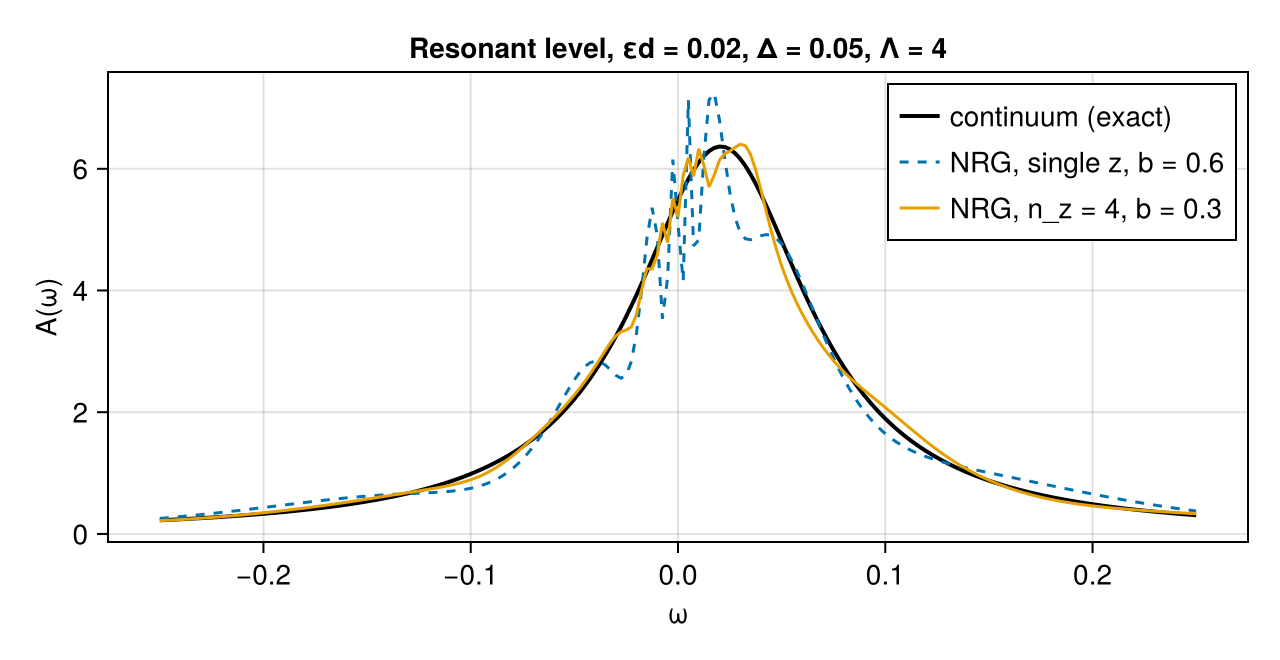

In [8]:
m = resonant_level(εd = 0.02, Δ = 0.05); T = 1e-4; N = chain_length_for(T; Λ = 4.0, margin = 4)
g = LogGrid(emin = 1e-7, emax = 10.0, ndec = 32); dd = cop(Mode(-1, :d))
Δ = 0.05; εd = 0.02
hyb(ω) = Δ / π * log(abs((1 + ω) / (1 - ω))) - im * Δ
Acont(ω) = -imag(1 / (ω - εd - hyb(ω))) / π
run = run_nrg(m, NRGParams(N = N, Nkeep = 64)); f = fdm(run; T = T)
r = psf(run, f, (dd, dd'); grid = g); rr = psf(run, f, (dd', dd); grid = g)
@printf("total weights: S[d,d†] + S[d†,d] - 1 = %.1e;  S[d,d†] - FDM sum rule = %.1e\n", r.total + rr.total - 1, r.total - r.meta[:sum_rule])
zs = zaveraged_psfs(m, NRGParams(N = N, Nkeep = 64), (dd, dd'); T = T, nz = 4, grid = g)
ω = collect(range(-0.25, 0.25; length = 201))
A1 = broaden(r, ω; b = 0.6) .+ broaden(rr, -ω; b = 0.6)
A4 = broaden(zs[[1, 2]], ω; b = 0.3) .+ broaden(zs[[2, 1]], -ω; b = 0.3)
dev1 = maximum(abs.(A1 .- Acont.(ω)) ./ Acont.(ω)); dev4 = maximum(abs.(A4 .- Acont.(ω)) ./ Acont.(ω))
@printf("broadened vs continuum, max relative deviation on |ω| ≤ 0.25: single z, b = 0.6: %.2f;  n_z = 4, b = 0.3: %.2f\n", dev1, dev4)
RESULTS["V5"] = (single_z = dev1, nz4 = dev4)
fig = Figure(size = (640, 330))
ax = Axis(fig[1, 1], xlabel = "ω", ylabel = "A(ω)", title = "Resonant level, εd = 0.02, Δ = 0.05, Λ = 4")
lines!(ax, ω, Acont.(ω); label = "continuum (exact)", color = :black, linewidth = 2)
lines!(ax, ω, A1; label = "NRG, single z, b = 0.6", linestyle = :dash)
lines!(ax, ω, A4; label = "NRG, n_z = 4, b = 0.3")
axislegend(ax; position = :rt)
savefig("v5_rlm", fig)

## V6. Internal consistency (P6–P8)

* The equivalent trace forms: Lee's slicing references (`:lee`) vs slicing every composite relative to its left
  endpoint (`:left`). Totals agree exactly; with truncation the forms are different approximations (positions agree to
  NRG accuracy, exactly in V4d). The two task schedules (`:depth`, `:breadth`) agree exactly.
* Total weights are independent of $z$.
* Convergence with $N_{\rm keep}$ towards the exact result.

4p totals, :lee vs :left: 1.6e-15;  histograms, :depth vs :breadth: 4.3e-18
⟨{d, d†}⟩ = 1 from the PSF totals for z = 0.25 … 1: 3.6e-15
N_keep =     8   2p: 2.9e-01   3p: 1.1e-01
N_keep =    16   2p: 7.6e-02   3p: 6.6e-02
N_keep =    32   2p: 4.0e-02   3p: 3.8e-02
N_keep =    64   2p: 5.4e-03   3p: 6.2e-03
N_keep =   128   2p: 7.2e-04   3p: 1.6e-03
N_keep =   256   2p: 1.8e-15   3p: 1.4e-15
N_keep =  1024   2p: 1.8e-15   3p: 1.4e-15


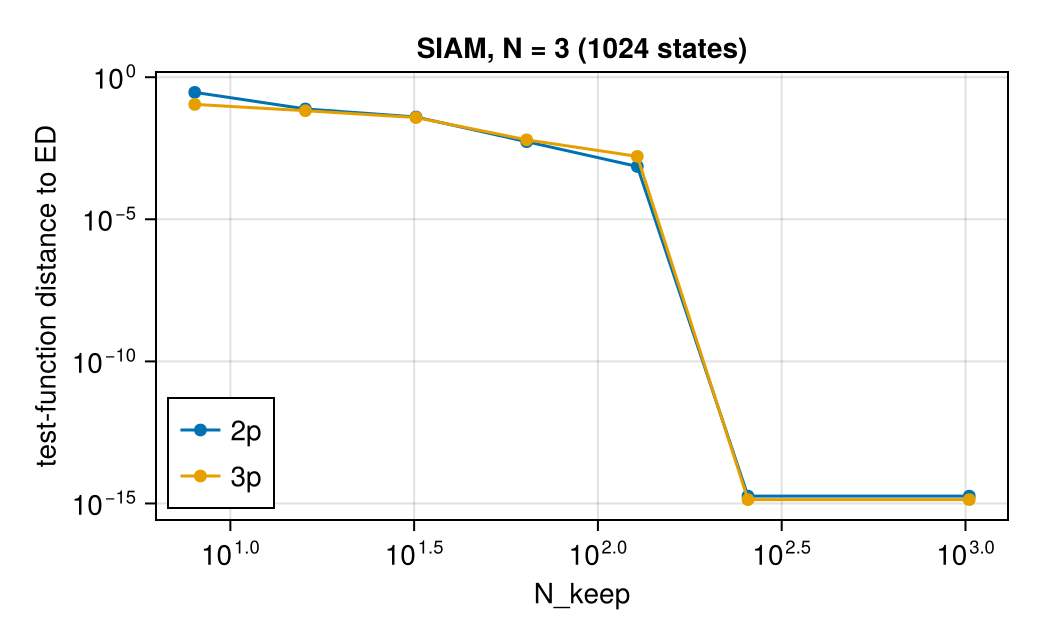

In [9]:
m = siam(U = 0.5, εd = -0.1, Δ = 0.1); run = run_nrg(m, NRGParams(N = 4, Nkeep = 24)); f = fdm(run; T = 0.02)
g = LogGrid(emin = 1e-6, emax = 10.0, ndec = 16)
ops4 = (d_(:up), dd_(:dn), d_(:dn), dd_(:up))
a = psf(run, f, ops4; grid = g); b = psf(run, f, ops4; grid = g, slicing = :left); c = psf(run, f, ops4; grid = g, schedule = :breadth)
@printf("4p totals, :lee vs :left: %.1e;  histograms, :depth vs :breadth: %.1e\n", abs(a.total - b.total), dict_maxdiff(hist_dict(a), hist_dict(c)))
ztot = maximum(begin
    run = run_nrg(m, NRGParams(N = 8, Nkeep = 64, z = z)); f = fdm(run; T = 1e-3)
    abs(psf(run, f, (d_(:up), dd_(:up)); grid = g).total + psf(run, f, (dd_(:up), d_(:up)); grid = g).total - 1)
end for z in (0.25, 0.5, 0.75, 1.0))
@printf("⟨{d, d†}⟩ = 1 from the PSF totals for z = 0.25 … 1: %.1e\n", ztot)
N = 3; T = 0.03; chs = wilson_chains(m, N); ed = model_ed(m, chs, N, T)
Nks = [8, 16, 32, 64, 128, 256, 1024]
errs = Dict(ℓ => Float64[] for ℓ in (2, 3))
for Nk in Nks
    run = run_nrg(m, NRGParams(N = N, Nkeep = Nk); chains = chs); f = fdm(run; T = T)
    for (ℓ, ops) in ((2, (d_(:up), dd_(:up))), (3, (d_(:up), dd_(:up), n_(:dn))))
        r = psf(run, f, ops; exact = true, max_terms = 20_000_000); P, w = ed_psf(ed, ops)
        push!(errs[ℓ], test_functions_error(r.positions, r.weights, P, w; ks = (0.5, 2.0, -3.0)))
    end
end
for (i, Nk) in enumerate(Nks); @printf("N_keep = %5d   2p: %.1e   3p: %.1e\n", Nk, errs[2][i], errs[3][i]); end
RESULTS["V6"] = (forms_total = abs(a.total - b.total), schedules = dict_maxdiff(hist_dict(a), hist_dict(c)), z = ztot, conv = errs)
fig = Figure(size = (520, 320))
ax = Axis(fig[1, 1], xscale = log10, yscale = log10, xlabel = "N_keep", ylabel = "test-function distance to ED", title = "SIAM, N = 3 (1024 states)")
scatterlines!(ax, Nks, max.(errs[2], 1e-16); label = "2p"); scatterlines!(ax, Nks, max.(errs[3], 1e-16); label = "3p")
axislegend(ax; position = :lb)
savefig("v6_convergence", fig)

## V7. Physics benchmarks: SIAM with box hybridization (P5, P6)

$U=0.5$, $\Delta=0.02$ ($U/\pi\Delta\approx8$), $\varepsilon_d=-U/2$, $\Lambda=4$. Impurity entropy and $T\chi$ from the
conventional shell-wise formulas (even/odd averaged) and from FDM thermal averages (z-averaged, $n_z=4$). The Friedel
sum rule $\pi\Delta A(0)=1$ is checked on the plateau $T\ll\omega\ll T_K$ (log-average) and at $\omega=0$ itself, where
discrete FDM data below $T$ cause a few-percent dip (also at $U=0$; Lee Sec. VII B).

S_imp: high T 1.3814 (ln 4 = 1.3863), local moment 0.6831 (ln 2 = 0.6931), lowest T 1.1e-05
T χ_imp: high T 0.1335 (1/8), local moment 0.2068 (→ 1/4), lowest T 3.9e-06
⟨n_d⟩ - 1 at particle-hole symmetry: 1.1e-15
Friedel: π Δ A on the plateau 0.9951, at ω = 0 0.9558


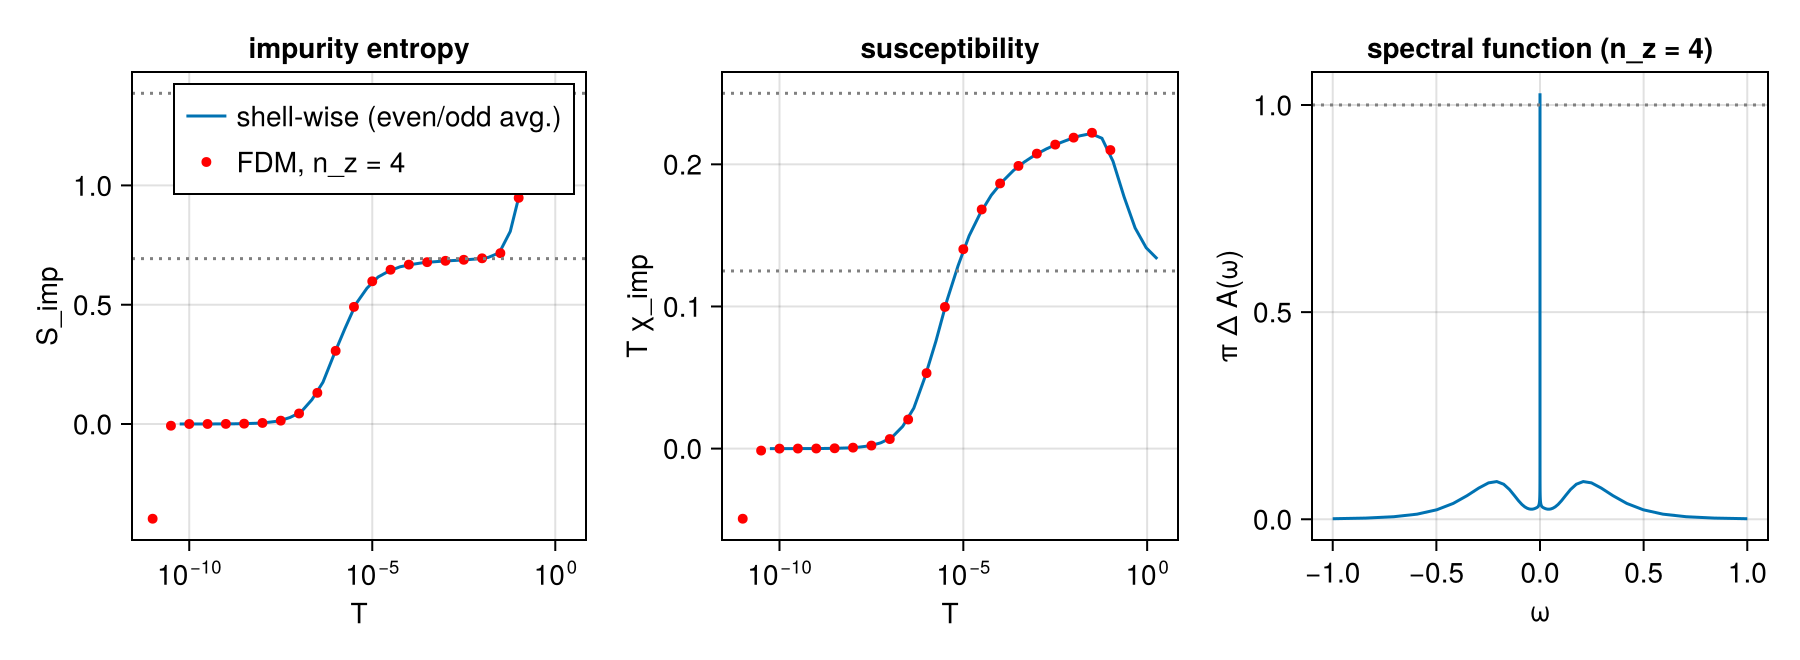

In [10]:
m = siam(U = 0.5, Δ = 0.02); T = 1e-9
p = NRGParams(N = chain_length_for(T; Λ = 4.0, margin = 6), Nkeep = 400)
run = run_nrg(m, p); runb = run_nrg(bath_model(m), p; chains = run.chains)
th = evenodd_average(impurity_thermodynamics_shell(run, runb))
Ts = 10.0 .^ range(-1, -11; length = 21)
tf = impurity_thermodynamics_zavg(m, p, Ts; nz = 4)
i_lm = findfirst(t -> t < 1e-3, th.T)
@printf("S_imp: high T %.4f (ln 4 = %.4f), local moment %.4f (ln 2 = %.4f), lowest T %.1e\n", th.entropy[1], log(4), th.entropy[i_lm], log(2), th.entropy[end])
@printf("T χ_imp: high T %.4f (1/8), local moment %.4f (→ 1/4), lowest T %.1e\n", th.Tchi[1], th.Tchi[i_lm], th.Tchi[end])
f = fdm(run; T = T)
@printf("⟨n_d⟩ - 1 at particle-hole symmetry: %.1e\n", thermal_average(run, f, n_(:up) + n_(:dn)) - 1)
g = LogGrid(emin = 1e-12, emax = 10.0, ndec = 32)
zs = zaveraged_psfs(m, p, (d_(:up), dd_(:up)); T = T, nz = 4, grid = g)
Aat(ω) = broaden(zs[[1, 2]], ω; b = 0.6) .+ broaden(zs[[2, 1]], -ω; b = 0.6)
ωp = 10 .^ range(-8, -6.5; length = 31)
plateau = sum(π * 0.02 .* Aat(ωp)) / length(ωp); fr0 = π * 0.02 * Aat([0.0])[1]
@printf("Friedel: π Δ A on the plateau %.4f, at ω = 0 %.4f\n", plateau, fr0)
RESULTS["V7"] = (S_high = th.entropy[1], S_lm = th.entropy[i_lm], S_low = th.entropy[end], Tchi_lm = th.Tchi[i_lm], plateau = plateau, fr0 = fr0)
fig = Figure(size = (900, 330))
ax1 = Axis(fig[1, 1], xscale = log10, xlabel = "T", ylabel = "S_imp", title = "impurity entropy")
lines!(ax1, th.T, th.entropy; label = "shell-wise (even/odd avg.)"); scatter!(ax1, tf.T, tf.entropy; label = "FDM, n_z = 4", color = :red, markersize = 7)
hlines!(ax1, [log(4), log(2)]; color = :gray, linestyle = :dot); axislegend(ax1; position = :rt)
ax2 = Axis(fig[1, 2], xscale = log10, xlabel = "T", ylabel = "T χ_imp", title = "susceptibility")
lines!(ax2, th.T, th.Tchi); scatter!(ax2, tf.T, tf.Tchi; color = :red, markersize = 7); hlines!(ax2, [1 / 8, 1 / 4]; color = :gray, linestyle = :dot)
ω = vcat(-reverse(10 .^ range(-9, 0; length = 120)), 10 .^ range(-9, 0; length = 120))
ax3 = Axis(fig[1, 3], xlabel = "ω", ylabel = "π Δ A(ω)", title = "spectral function (n_z = 4)")
lines!(ax3, ω, π * 0.02 .* Aat(ω)); hlines!(ax3, [1.0]; color = :gray, linestyle = :dot)
savefig("v7_siam", fig)

### A 4p PSF (Lee Fig. 3 analogue)

The opposite-spin PSF $S[d_\uparrow,d^\dagger_\uparrow,d_\downarrow,d^\dagger_\downarrow](\varepsilon_1,\varepsilon_2=0,\varepsilon_3)$
for $U=0$ and $U/\Delta=5$ ($\Delta=0.04$, $T=10^{-3}$, $\Lambda=4$, $n_{\rm dec}=8$, reduced $N_{\rm keep}=120$ to
keep the notebook short). For $U=0$ Wick's theorem makes it the product $S[d_\uparrow,d^\dagger_\uparrow](\varepsilon_1)
S[d_\downarrow,d^\dagger_\downarrow](\varepsilon_3)\delta(\varepsilon_2)$, a square pattern on the log axes (Lee p. 26).

U = 0: max |S₄(ε₁,0,ε₃) - S₂(ε₁) S₂(ε₃)| / max S₄ = 4.09e-04 (NRG truncation and binning)
U = 0.00: total 0.250000000000 vs FDM sum rule 0.250000000000 (82.8 s)
U = 0.20: total 0.137193682742 vs FDM sum rule 0.137193682742 (168.1 s)


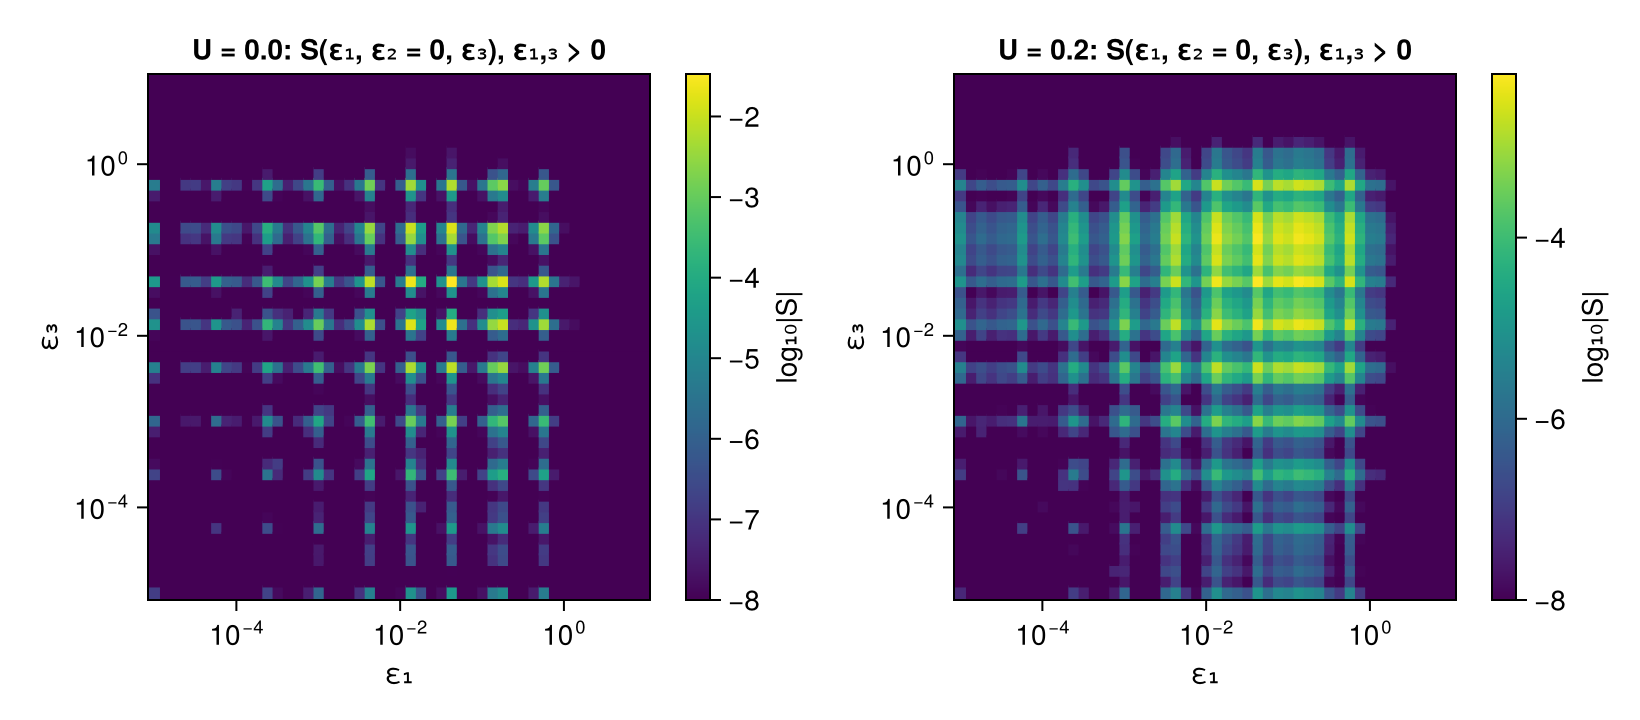

In [11]:
g8 = LogGrid(emin = 1e-5, emax = 10.0, ndec = 8)
heat = Dict{Float64,Any}()
for Uv in (0.0, 0.2)
    m = siam(U = Uv, Δ = 0.04); T = 1e-3
    run = run_nrg(m, NRGParams(N = chain_length_for(T; Λ = 4.0, margin = 4), Nkeep = 120)); f = fdm(run; T = T)
    r = psf(run, f, (d_(:up), dd_(:up), d_(:dn), dd_(:dn)); grid = g8, sparse = false)
    H = histogram(r)
    heat[Uv] = (H = H[:, zerobin(g8), :], total = r.total, sum_rule = r.meta[:sum_rule], time = r.meta[:time])
    if Uv == 0.0
        a = histogram(psf(run, f, (d_(:up), dd_(:up)); grid = g8)); b = histogram(psf(run, f, (d_(:dn), dd_(:dn)); grid = g8))
        @printf("U = 0: max |S₄(ε₁,0,ε₃) - S₂(ε₁) S₂(ε₃)| / max S₄ = %.2e (NRG truncation and binning)\n",
                maximum(abs.(heat[Uv].H .- a * b')) / maximum(abs.(heat[Uv].H)))
    end
    @printf("U = %.2f: total %.12f vs FDM sum rule %.12f (%.1f s)\n", Uv, r.total, r.meta[:sum_rule], r.meta[:time])
end
c8 = centres(g8)
pos = findall(>(0), c8)
fig = Figure(size = (820, 360))
for (k, Uv) in enumerate((0.0, 0.2))
    ax = Axis(fig[1, 2k - 1], xscale = log10, yscale = log10, xlabel = "ε₁", ylabel = "ε₃", title = "U = $Uv: S(ε₁, ε₂ = 0, ε₃), ε₁,₃ > 0")
    Hp = heat[Uv].H[pos, pos]
    hm = heatmap!(ax, c8[pos], c8[pos], log10.(abs.(Hp) .+ 1e-12); colorrange = (-8, log10(maximum(abs.(Hp)))))
    Colorbar(fig[1, 2k], hm; label = "log₁₀|S|")
end
savefig("v7_4p_psf", fig)

## V8. External benchmark: published mpNRG PSFs (Frankenbach et al., LMU Open Data 613)

Dataset `siam05_U0.05_T0.05_Delta0.0318` of Frankenbach, Ritter, Pelz, Ritz, von Delft & Ge,
arXiv:2506.13359 (https://data.ub.uni-muenchen.de/613/), produced with the MuNRG/QSpace mpNRG code.
**Format, as inspected:** MATLAB 7.3 (HDF5) files; `mpNRG.mat` holds the parameters ($\Lambda=4$, $N=12$,
$N_{\rm keep}=300$ multiplets with charge U(1) × spin SU(2), $n_z=2$, $T=U=0.05$, $\varepsilon_d=-U/2$; its `Delta`
field is $\Delta/\pi$ as the dataset README warns, the true $\Delta=0.0318$ follows from `Rhoin`, a box of half-width 1).
`PSF_((O1,…)).mat` holds `odisc` (Lee's grid with $n_{\rm dec}=8$, $|\varepsilon|$ from $10^{-21/8}$ to $10^{3/2}$) and
`Adisc` (cell). The 2p PSFs are full PSFs; the 4p PSFs (`4pt/`) are **connected** parts $S-S^{\rm dis}$ (Lee Sec. VI A),
with two spin flavors per file: [1] = $\sigma\sigma$, [2] = $\sigma\sigma'$ (identified from their totals:
$\sum S^{\rm con}[d_\sigma,d^\dagger_\sigma,d_\sigma,d^\dagger_\sigma]=0$ exactly, and
$\sum S^{\rm con}[d_\uparrow,d^\dagger_\uparrow,d_\downarrow,d^\dagger_\downarrow]=\langle n_\uparrow n_\downarrow\rangle-\tfrac14$).
Operator names: `F1` = $d_\uparrow$, `F3` = $d_\downarrow$ (flavor 2) or $d_\uparrow$ (flavor 1), `Q1` = $[d_\uparrow, U n_\uparrow n_\downarrow]$
(identified from $\langle qq^\dagger\rangle$). **Binning:** `bin_info = 'bary'` — each peak is split between its two
neighbouring grid points linearly in $\ln|\varepsilon|$ (identified below: it reproduces the data far better than
centre binning or linear splitting), not Lee's centre binning.

What can be compared: total weights (exact identities), the $\varepsilon_1$ and $\varepsilon_3$ marginals of the
connected 4p parts (the disconnected terms factorize there into 2p PSFs times totals, so no rebinning is needed), and
2p histograms after identical binning (we apply 'bary' to our exact-mode positions). Our NRG uses abelian
U(1)×U(1) symmetries with $N_{\rm keep}$ states (not multiplets), the same $\Lambda$, $N$, $z\in\{\tfrac12,1\}$ and
Žitko–Pruschke discretization. Results: `scripts/v8_benchmark.jl` → `figures/mpnrg/v8_results.jld2`.

Nkeep  400  F1_F1dag  total ours 0.500000 ref 0.500000 | max bin dev / max bin: bary 0.075, centre 0.347
Nkeep  400  Q1_Q1dag  total ours 0.000715 ref 0.000716 | max bin dev / max bin: bary 0.087, centre 0.253
Nkeep  400  F1_Q1dag  total ours 0.014305 ref 0.014311 | max bin dev / max bin: bary 0.093, centre 0.383
Nkeep  800  F1_F1dag  total ours 0.500000 ref 0.500000 | max bin dev / max bin: bary 0.074, centre 0.355
Nkeep  800  Q1_Q1dag  total ours 0.000715 ref 0.000716 | max bin dev / max bin: bary 0.105, centre 0.243
Nkeep  800  F1_Q1dag  total ours 0.014304 ref 0.014311 | max bin dev / max bin: bary 0.107, centre 0.387


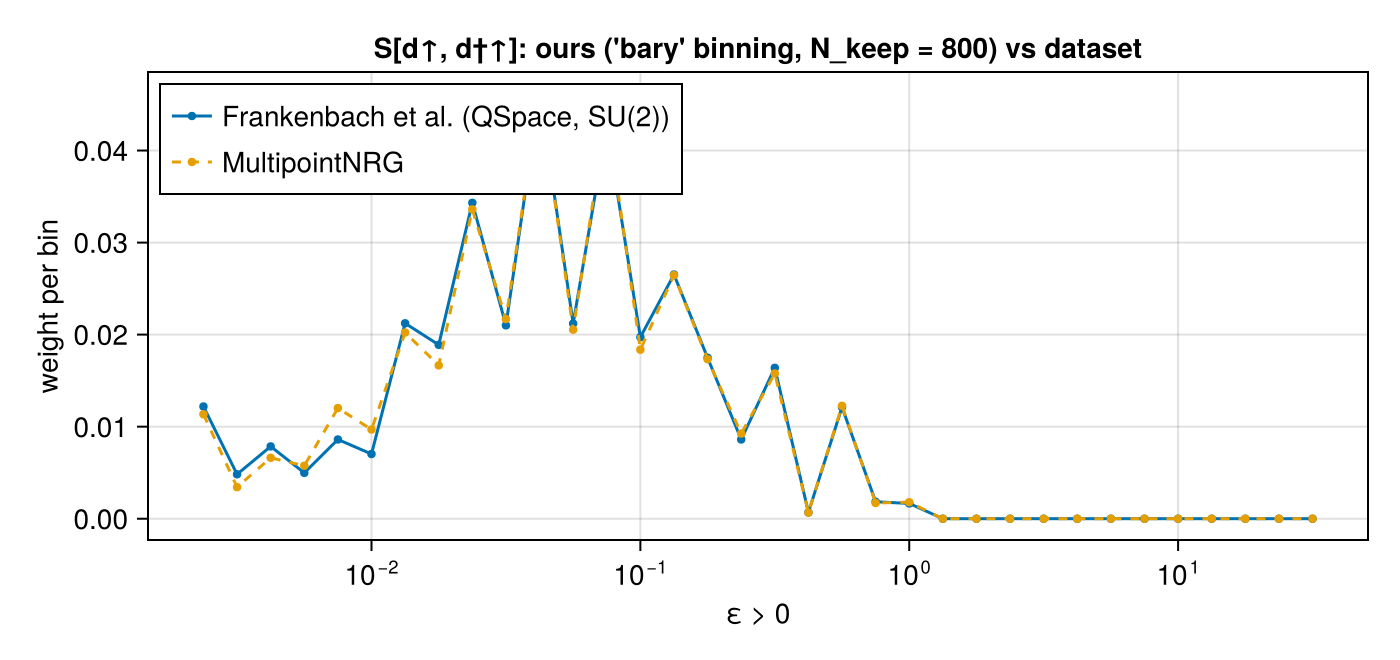

In [12]:
V8FILE = joinpath(FIG, "v8_results.jld2")
if !isfile(V8FILE)
    println("V8 results not found; run scripts/v8_benchmark.jl")
else
    R = load(V8FILE, "results"); od = R["odisc"]
    ref2 = R["ref_psf2"]
    for Nk in (400, 800)
        haskey(R, "psf2_bary_Nk$Nk") || continue
        hb = R["psf2_bary_Nk$Nk"]; hc = R["psf2_centre_Nk$Nk"]
        for nm in ("F1_F1dag", "Q1_Q1dag", "F1_Q1dag")
            A = ref2[nm]; mx = maximum(abs.(A))
            @printf("Nkeep %4d  %-9s total ours %.6f ref %.6f | max bin dev / max bin: bary %.3f, centre %.3f\n",
                    Nk, nm, sum(hb[nm]), sum(A), maximum(abs.(hb[nm] .- A)) / mx, maximum(abs.(hc[nm] .- A)) / mx)
        end
    end
    fig = Figure(size = (700, 330))
    ax = Axis(fig[1, 1], xscale = log10, xlabel = "ε > 0", ylabel = "weight per bin", title = "S[d↑, d†↑]: ours ('bary' binning, N_keep = 800) vs dataset")
    ip = findall(>(0), od)
    scatterlines!(ax, od[ip], ref2["F1_F1dag"][ip]; label = "Frankenbach et al. (QSpace, SU(2))", markersize = 6)
    haskey(R, "psf2_bary_Nk800") && scatterlines!(ax, od[ip], R["psf2_bary_Nk800"]["F1_F1dag"][ip]; label = "MultipointNRG", markersize = 6, linestyle = :dash)
    axislegend(ax; position = :lt)
    savefig("v8_2p", fig)
end

N_keep 400: connected 4p totals, 48 PSFs: max |Δ| = 1.2e-04, max relative (|total| > 1e-3) = 0.003
N_keep 800: connected 4p totals, 48 PSFs: max |Δ| = 1.5e-04, max relative (|total| > 1e-3) = 0.004
σσ′: ε₁ / ε₃ marginals of the connected 4p PSFs (24 permutations, N_keep = 100, smoothed): max rel. dev. 0.108 / 0.108
σσ: connected marginals vanish exactly (single mode); dataset ≤ 8e-17, ours ≤ 1.4e-05 = 1.8e-03 of the σσ′ scale (24 permutations)
dataset: its ε₁ marginal vs its own 2p combination: 1.3e-14;  ours vs dataset for that 2p combination (smoothed): 0.098


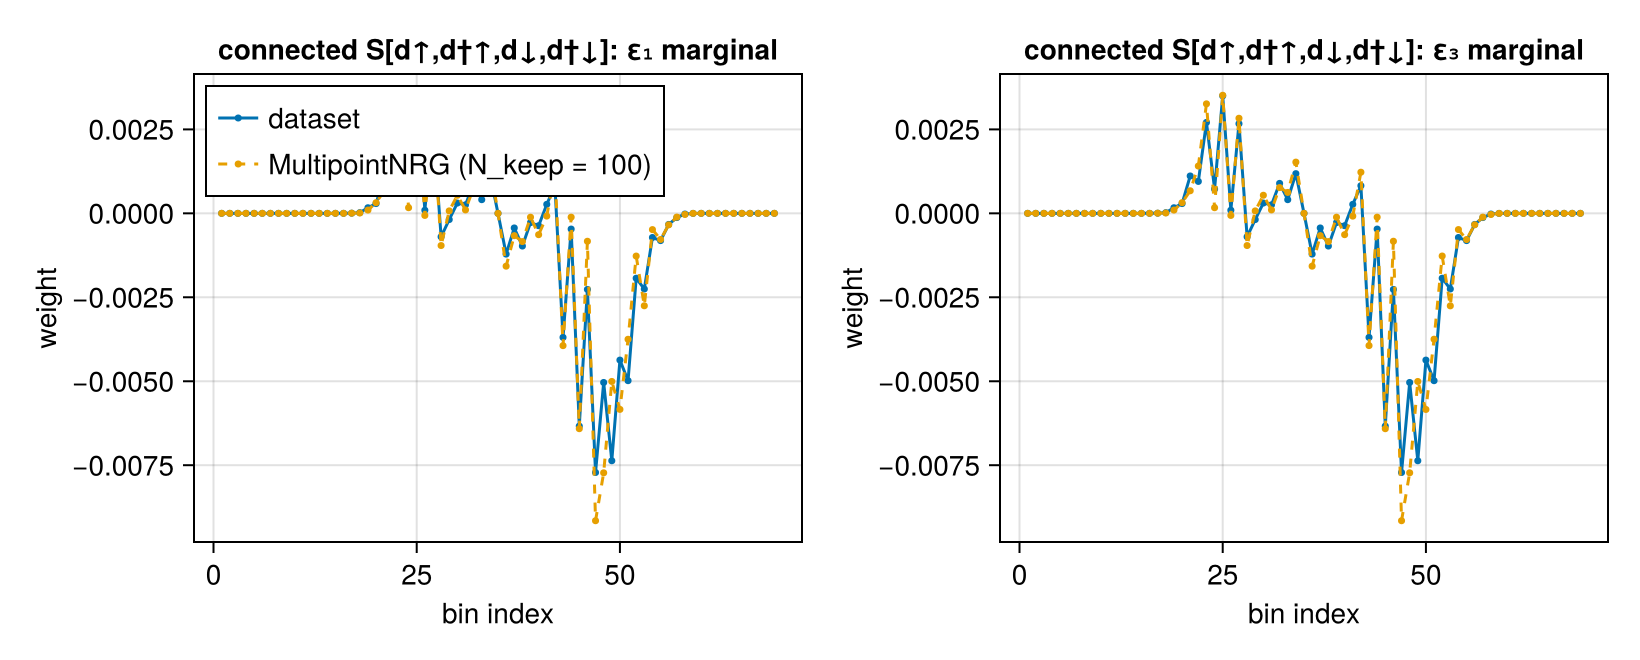

In [13]:
if isfile(V8FILE)
    perms = all_perms(4)
    rm = R["ref_marginals"]
    for Nk in (400, 800)
        key = "con_totals_Nk$Nk"; haskey(R, key) || continue
        tot = R[key]
        dev = Float64[]; devrel = Float64[]
        for fl in (1, 2), p in perms
            ours = tot["Nk$(Nk)_fl$(fl)_" * join(p)]; theirs = rm["fl$(fl)_" * join(p)]["total"]
            push!(dev, abs(ours - theirs)); abs(theirs) > 1e-3 && push!(devrel, abs(ours - theirs) / abs(theirs))
        end
        @printf("N_keep %d: connected 4p totals, 48 PSFs: max |Δ| = %.1e, max relative (|total| > 1e-3) = %.3f\n", Nk, maximum(dev), maximum(devrel))
    end
    if haskey(R, "marginals") && !isempty(R["marginals"])
        mg = R["marginals"]
        # common log-Gaussian smoothing of both marginals (the binning rules differ: centre vs 'bary')
        sm(x) = [od[i] == 0 ? x[i] : sum(x[j] * exp(-((log(abs(od[i])) - log(abs(od[j]))) / 0.5)^2) for j in eachindex(od) if od[j] * od[i] > 0) for i in eachindex(od)]
        rel(a, b) = maximum(abs.(sm(a) .- sm(b))) / maximum(abs.(sm(b)))
        k2 = [k for k in keys(mg) if startswith(k, "fl2")]; k1 = [k for k in keys(mg) if startswith(k, "fl1")]
        b1 = [rel(mg[k]["m1"], rm[k]["m1"]) for k in k2]; b3 = [rel(mg[k]["m3"], rm[k]["m3"]) for k in k2]
        z1 = maximum(max(maximum(abs, mg[k]["m1"]), maximum(abs, mg[k]["m3"])) for k in k1; init = 0.0)
        @printf("σσ′: ε₁ / ε₃ marginals of the connected 4p PSFs (%d permutations, N_keep = %d, smoothed): max rel. dev. %.3f / %.3f\n",
                length(k2), R["Nkeep4p"], maximum(b1), maximum(b3))
        sc = maximum(maximum(abs, rm[k]["m1"]) for k in k2)
        @printf("σσ: connected marginals vanish exactly (single mode); dataset ≤ %.0e, ours ≤ %.1e = %.1e of the σσ′ scale (%d permutations)\n",
                maximum(maximum(abs, rm[k]["m1"]) for k in k1), z1, z1 / sc, length(k1))
        # the dataset's 4p marginals are exactly combinations of its 2p PSFs: Σ_{ε₂,ε₃} S_con[d↑,d†↑,d↓,d†↓]
        # = S[d↑, d†↑(1-n↓)] - S[d↑,d†↑]⟨d↓d†↓⟩, with d†↑ n↓ = q†↑/U; so the 4p difference is the 2p difference
        U8 = R["U"]; ref2 = R["ref_psf2"]; hb = R["psf2_bary_Nk800"]
        pr(h) = h["F1_F1dag"] .- h["F1_Q1dag"] ./ U8 .- h["F1_F1dag"] ./ 2
        @printf("dataset: its ε₁ marginal vs its own 2p combination: %.1e;  ours vs dataset for that 2p combination (smoothed): %.3f\n",
                maximum(abs.(rm["fl2_1234"]["m1"] .- pr(ref2))) / maximum(abs.(pr(ref2))), rel(pr(hb), pr(ref2)))
        RESULTS["V8"] = (marg_max = (maximum(b1), maximum(b3)), fl1_zero = z1 / sc, twop_comb = rel(pr(hb), pr(ref2)))
        k = "fl2_1234"
        if haskey(mg, k)
            fig = Figure(size = (820, 330))
            for (i, (lab, key)) in enumerate((("ε₁", "m1"), ("ε₃", "m3")))
                ax = Axis(fig[1, i], xlabel = "bin index", ylabel = "weight", title = "connected S[d↑,d†↑,d↓,d†↓]: $lab marginal")
                scatterlines!(ax, 1:length(od), rm[k][key]; label = "dataset", markersize = 5)
                scatterlines!(ax, 1:length(od), mg[k][key]; label = "MultipointNRG (N_keep = $(R["Nkeep4p"]))", markersize = 5, linestyle = :dash)
                i == 1 && axislegend(ax; position = :lt)
            end
            savefig("v8_4p_marginals", fig)
        end
    end
end

## Hooks (Sec. 5.10) and export to `HubbardAtom` kernels (P9)

The per-shell hook interface exposes isometries, $\bar\rho^n_{KK}$, the projected operators, the KK refinement map and
the sliced composites being carried. The example hook records the singular values of every carried composite slice
(no compression is done). Exported PSFs feed `HubbardAtom`'s Matsubara kernel.

In [14]:
m = siam(U = 0.5, εd = -0.1, Δ = 0.1); run = run_nrg(m, NRGParams(N = 8, Nkeep = 48)); f = fdm(run; T = 1e-3)
g = LogGrid(emin = 1e-6, emax = 10.0, ndec = 16)
rec = SingularValueRecorder()
r = psf(run, f, (d_(:up), dd_(:up), n_(:dn)); grid = g, schedule = :breadth, hooks = [rec])
fig = Figure(size = (620, 330))
ax = Axis(fig[1, 1], yscale = log10, xlabel = "shell n", ylabel = "largest singular value of a carried slice", title = "3p KKD/KDK composites carried through the sweep")
for (n, v) in sort(collect(rec.data))
    isempty(v) && continue
    scatter!(ax, fill(n, length(v)) .+ 0.25 .* (rand(length(v)) .- 0.5), [max(isempty(x[6]) ? 0.0 : first(x[6]), 1e-16) for x in v]; markersize = 3, color = (:steelblue, 0.4))
end
savefig("hooks_singular_values", fig)
@printf("carried composite slices seen by the hook: %d (over %d shells)\n", sum(length, values(rec.data)), length(rec.data))
# export: Matsubara G(iν) from mpNRG PSFs through HubbardAtom's kernel, vs HubbardAtom's own PSFs
U = 0.4; T = 0.05; m = siam(U = U, Δ = 0.1); run = run_nrg(m, NRGParams(N = 1, Nkeep = typemax(Int))); f = fdm(run; T = T)
E, Vk = chain_star(run.chains[1], 1); ha = HA.AIMModel(U, 1 / T, E, Vk); du = HA.operators(ha).c[1]
rs = psfs(run, f, (d_(:up), dd_(:up)); exact = true)
cache = [HA.PermutedPSF(p, HA.permutation_sign(p, [true, true]), [HA.PSFTerm(r.positions[:, j], ComplexF64(r.weights[j]), Int[]) for j in eachindex(r.weights)]) for (p, r) in rs]
errG = maximum(abs(HA.correlator(ha, (du, du'), [HA.fermionic_freq(n), HA.MatsubaraFreq(-(2n + 1))]; cache = cache) -
                   HA.correlator(ha, (du, du'), [HA.fermionic_freq(n), HA.MatsubaraFreq(-(2n + 1))])) for n in 0:5)
@printf("G(iν) through HubbardAtom kernels from exported mpNRG PSFs vs HubbardAtom: %.1e\n", errG)
RESULTS["export"] = errG

carried composite slices seen by the hook: 1174 (over 10 shells)
G(iν) through HubbardAtom kernels from exported mpNRG PSFs vs HubbardAtom: 5.5e-14


5.477035541383191e-14

## Performance (P10)

Wall time of the forward sweep and of one PSF per $\ell$ for the SIAM ($U=0.2$, $\Delta=0.04$, $\Lambda=4$,
$T=10^{-4}$, grid $n_{\rm dec}=8$) versus $N_{\rm keep}$, with the 4 threads of this machine, compared with Lee's cost
estimates ($\sim N$ shell traces, $\sim N^2$ for the 2p refinements, $\sim N^3$ for the 4p terms that need a 3p PSF for
every $n$, Lee p. 18).

In [15]:
m = siam(U = 0.2, Δ = 0.04); T = 1e-4; N = chain_length_for(T; Λ = 4.0, margin = 4)
g = LogGrid(emin = 1e-6, emax = 10.0, ndec = 8)
rows = []
for Nk in (25, 50, 100)
    t0 = time(); run = run_nrg(m, NRGParams(N = N, Nkeep = Nk)); tn = time() - t0; f = fdm(run; T = T)
    ts = Float64[]; cs = []
    for ops in ((d_(:up), dd_(:up)), (d_(:up), dd_(:up), n_(:dn)), (d_(:up), dd_(:up), d_(:dn), dd_(:dn)))
        r = psf(run, f, ops; grid = g); push!(ts, r.meta[:time]); push!(cs, r.meta[:cost])
    end
    push!(rows, (Nk, tn, ts, cs))
end
println("N = $N")
@printf("%6s %10s %10s %10s %10s   %s\n", "Nkeep", "sweep [s]", "2p [s]", "3p [s]", "4p [s]", "4p cost (traces / composites / slice refinements)")
for (Nk, tn, ts, cs) in rows
    @printf("%6d %10.2f %10.2f %10.2f %10.2f   %d / %d / %d\n", Nk, tn, ts..., cs[3][:traces], cs[3][:composites], cs[3][:refinements])
end
RESULTS["perf"] = rows

N = 18
 Nkeep  sweep [s]     2p [s]     3p [s]     4p [s]   4p cost (traces / composites / slice refinements)
    25       0.18       0.01       0.28      29.84   249503 / 1917 / 373258
    50       0.14       0.01       0.67      70.59   320227 / 1917 / 453614
   100       0.19       0.02       1.51     248.29   313028 / 1725 / 631569


3-element Vector{Any}:
 (25, 0.1791520118713379, [0.0064470767974853516, 0.2767319679260254, 29.837769031524658], Any[Dict{Symbol, Any}(:traces => 736), Dict{Symbol, Any}(:refinements => 3318, :composites => 76, :traces => 14530), Dict{Symbol, Any}(:refinements => 373258, :composites => 1917, :traces => 249503)])
 (50, 0.1365208625793457, [0.012455940246582031, 0.6709399223327637, 70.5869619846344], Any[Dict{Symbol, Any}(:traces => 914), Dict{Symbol, Any}(:refinements => 3614, :composites => 76, :traces => 18425), Dict{Symbol, Any}(:refinements => 453614, :composites => 1917, :traces => 320227)])
 (100, 0.1924910545349121, [0.022891998291015625, 1.505791187286377, 248.28968906402588], Any[Dict{Symbol, Any}(:traces => 1068), Dict{Symbol, Any}(:refinements => 4154, :composites => 76, :traces => 19303), Dict{Symbol, Any}(:refinements => 631569, :composites => 1725, :traces => 313028)])

In [16]:
for (k, v) in sort(collect(RESULTS); by = first)
    println(rpad(k, 10), v isa AbstractFloat ? @sprintf("%.1e", v) : v)
end

V1_block  9.7e-16
V1_signs  6.7e-14
V2        (sumrule = 0.0, moments = 1.464441778069256e-154, ode = 1.284681829996939e-13)
V3        Dict("4p binned" => 3.1086244689504383e-15, "logZ" => 1.1546319456101628e-14, "energies" => 5.329070518200751e-15, "3p exact" => 8.537231110635769e-15, "thermal" => 4.274358644806853e-15, "3p binned" => 2.3314683517128287e-15, "4p exact" => 1.4404796127135062e-14, "2p binned" => 3.3584246494910985e-15, "2p exact" => 1.0677647859561945e-14)
V3bc      (b = 4.747979617071236e-14, c = 2.5107982731322426e-14)
V4        (a = 6.328271240363392e-15, b = 1.3788738309364788e-15, c = 8.557930018452004e-16, d = 2.0719346643846432e-14)
V5        (single_z = 0.3442639018500329, nz4 = 0.12528866768569913)
V6        (forms_total = 1.609823385706477e-15, schedules = 4.336808689942018e-18, z = 3.552713678800501e-15, conv = Dict(3 => [0.11017285757957809, 0.06599200570765237, 0.03793917277596343, 0.006239128702559454, 0.0016325241266064935, 1.3668035872266427e-15, 1.36680